In [1]:
!pip install ucimlrepo scikit-learn matplotlib seaborn pandas numpy


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Project setup and imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_curve,
                             roc_auc_score, ConfusionMatrixDisplay)
from sklearn.neural_network import MLPClassifier
import pandas as pd
from ucimlrepo import fetch_ucirepo

# DATA VISUALIZATIONS

### 1. BASIC DATA EXPLORATION & DATA CLEANING

In [3]:
# Fetch dataset
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)

# Data (as pandas dataframes)
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# Combine into a single dataframe
df = pd.concat([X, y], axis=1)

feature_names = [
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean',
    'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
    'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst',
    'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]

df.columns = feature_names + ['Diagnosis']

In [4]:
print(f"\nDataset Shape: {df.shape}")
print(f"\nColumn Names:\n{df.columns.tolist()}")
print(f"\nFirst few rows:")
print(df.head())
print(f"\nData Types:\n{df.dtypes}")
print(f"\nMissing Values:\n{df.isnull().sum()}")


Dataset Shape: (569, 31)

Column Names:
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Diagnosis']

First few rows:
   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4  

In [5]:
# Remove columns that are entirely NaN or have too many missing values
print("\n[CLEANING DATA]")
initial_shape = df.shape
df = df.dropna(axis=1, how='all')  # Drop columns with all NaN
print(f"Dropped columns with all NaN values: {initial_shape[1] - df.shape[1]} columns")

# Remove 'Unnamed' columns
unnamed_cols = [col for col in df.columns if 'Unnamed' in col]
if unnamed_cols:
    df = df.drop(columns=unnamed_cols)
    print(f"Dropped unnamed columns: {unnamed_cols}")

# Remove 'id' column if present
if 'id' in df.columns:
    df = df.drop('id', axis=1)
    print("Dropped 'id' column")

# Handle missing values
numeric_cols = df.select_dtypes(include=[np.number]).columns

# Handle zero values (replace with column mean)
zero_counts = (df[numeric_cols] == 0).sum()
columns_with_zeros = zero_counts[zero_counts > 0]

if len(columns_with_zeros) > 0:
    print(f"\nFound zero values in {len(columns_with_zeros)} columns")

    for col in columns_with_zeros.index:
        zero_mask = df[col] == 0
        if zero_mask.any():
            # Calculate mean excluding zeros
            col_mean = df[col][df[col] != 0].mean()
            df.loc[zero_mask, col] = col_mean

    print(f"Replaced {zero_counts.sum()} zero values with column means")
else:
    print("No zero values found in numeric columns")

print(f"\nCleaned Dataset Shape: {df.shape}")
print(f"\nRemaining Missing Values:\n{df.isnull().sum()[df.isnull().sum() > 0]}")

print(f"\nBasic Statistics:\n{df.describe()}")


[CLEANING DATA]
Dropped columns with all NaN values: 0 columns

Found zero values in 6 columns
Replaced 78 zero values with column means

Cleaned Dataset Shape: (569, 31)

Remaining Missing Values:
Series([], dtype: int64)

Basic Statistics:
       radius_mean  texture_mean  perimeter_mean    area_mean  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       smoothness_mean  compactness_mean  concavity_mean  concave_points_mean  \
count       569.000000        569.000000      569.000000           569.000000   
mean     

### 2. TARGET VARIABLE ANALYSIS

In [6]:
print(df['Diagnosis'].value_counts())
print(f"\nPercentages:\n{df['Diagnosis'].value_counts(normalize=True) * 100}")

Diagnosis
B    357
M    212
Name: count, dtype: int64

Percentages:
Diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


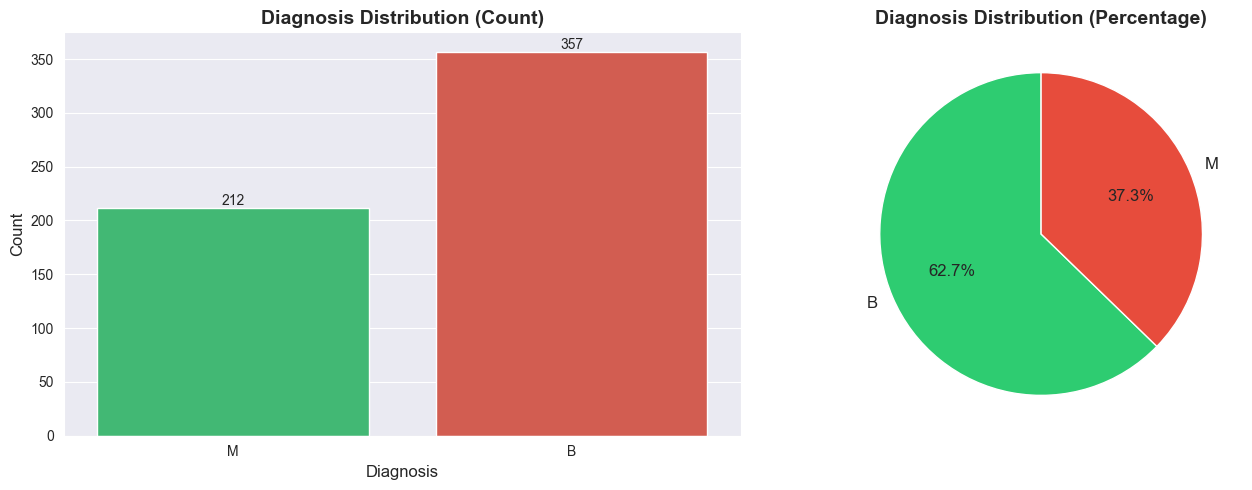

In [7]:
# Plot 1: Diagnosis Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
sns.countplot(data=df, x='Diagnosis', palette=['#2ecc71', '#e74c3c'], hue='Diagnosis', ax=axes[0])
axes[0].set_title('Diagnosis Distribution (Count)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Diagnosis', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
for container in axes[0].containers:
    axes[0].bar_label(container)

# Pie chart
diagnosis_counts = df['Diagnosis'].value_counts()
colors = ['#2ecc71', '#e74c3c']
axes[1].pie(diagnosis_counts, labels=diagnosis_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, textprops={'fontsize': 12})
axes[1].set_title('Diagnosis Distribution (Percentage)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### 3. FEATURE ANALYSIS - Mean Features

In [8]:
# Get mean features (columns ending with _mean)
mean_features = [col for col in df.columns if 'mean' in col.lower()]
print(f"\nAnalyzing features: {mean_features}")


Analyzing features: ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean']


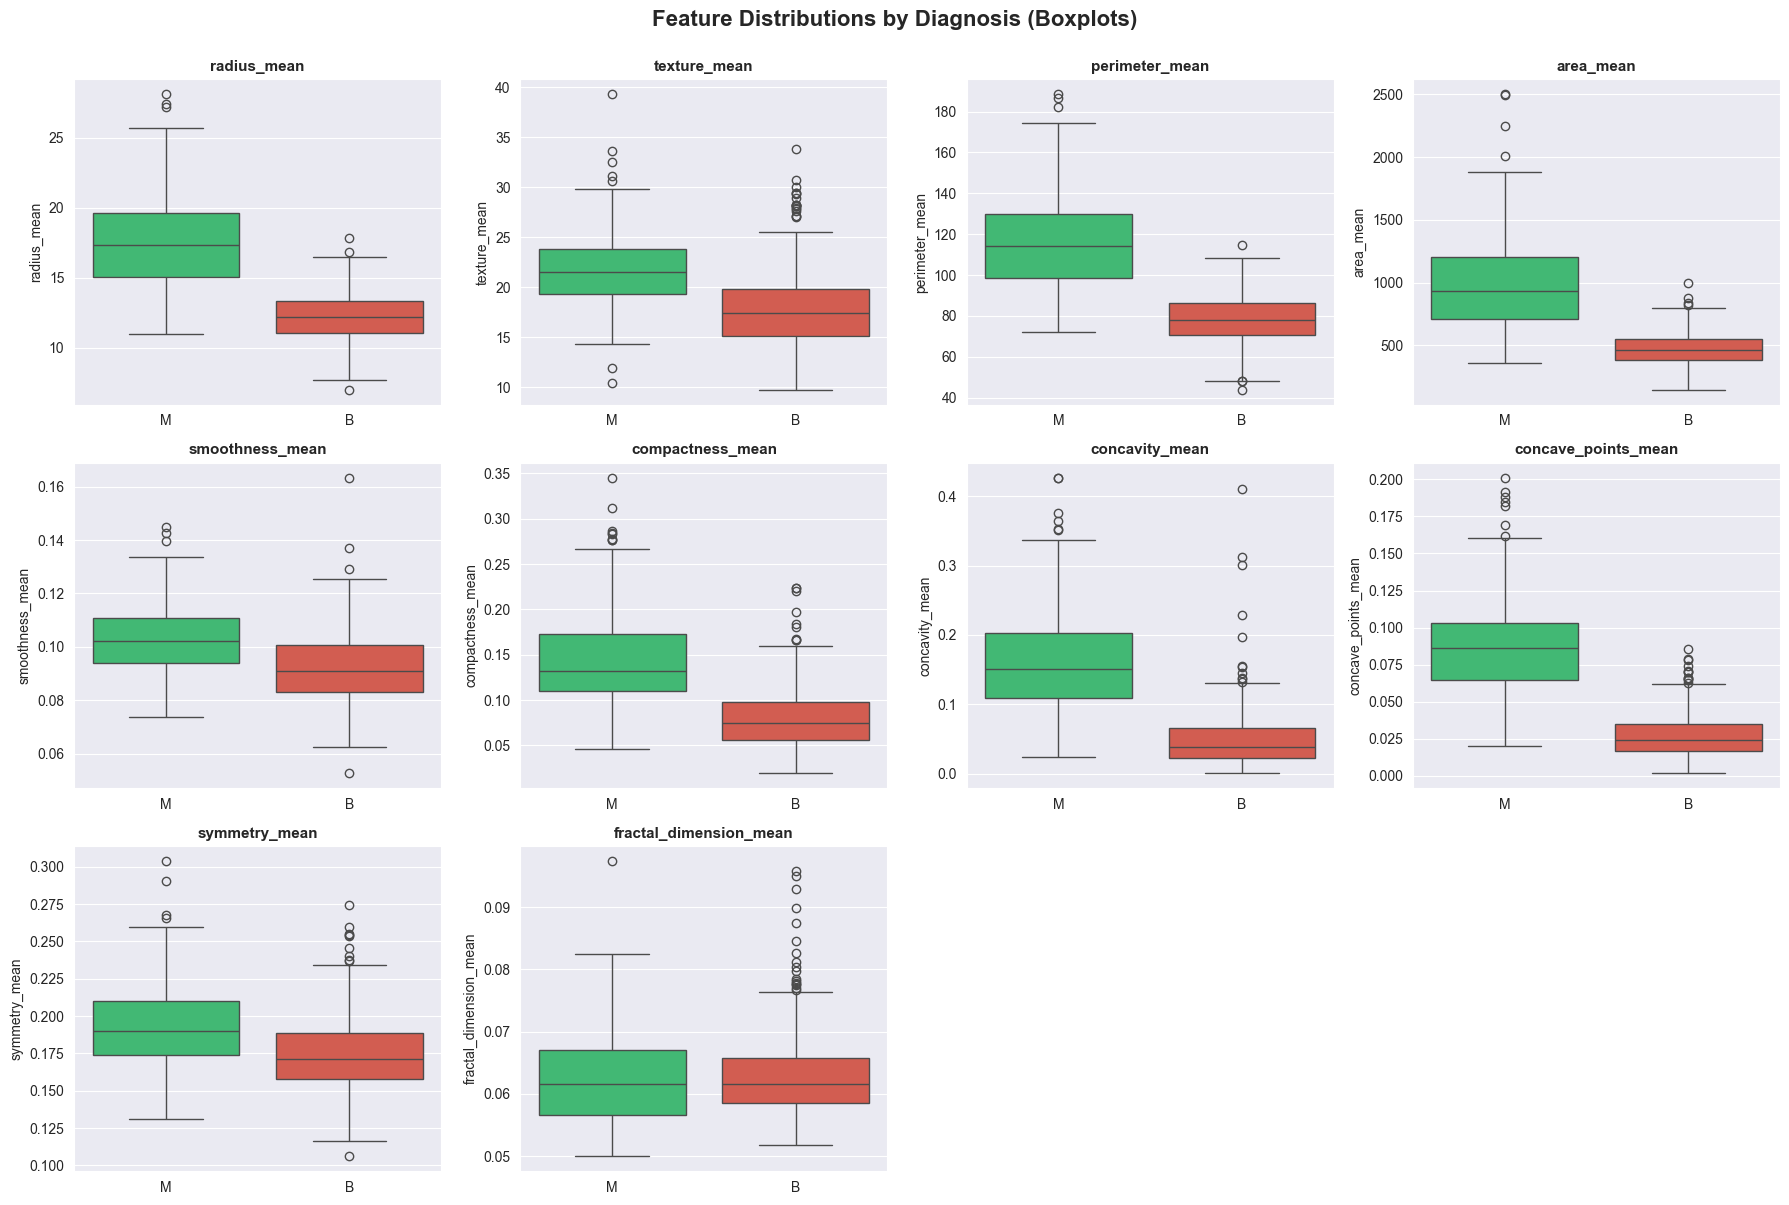

In [9]:
# Plot 2: Distribution of Mean Features by Diagnosis
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.ravel()

for idx, feature in enumerate(mean_features[:12]):
    if feature in df.columns:
        sns.boxplot(data=df, x='Diagnosis', y=feature, palette=['#2ecc71', '#e74c3c'], ax=axes[idx], hue='Diagnosis')
        axes[idx].set_title(f'{feature}', fontsize=11, fontweight='bold')
        axes[idx].set_xlabel('')

# Remove empty subplots
for idx in range(len(mean_features), 12):
    fig.delaxes(axes[idx])

plt.suptitle('Feature Distributions by Diagnosis (Boxplots)', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

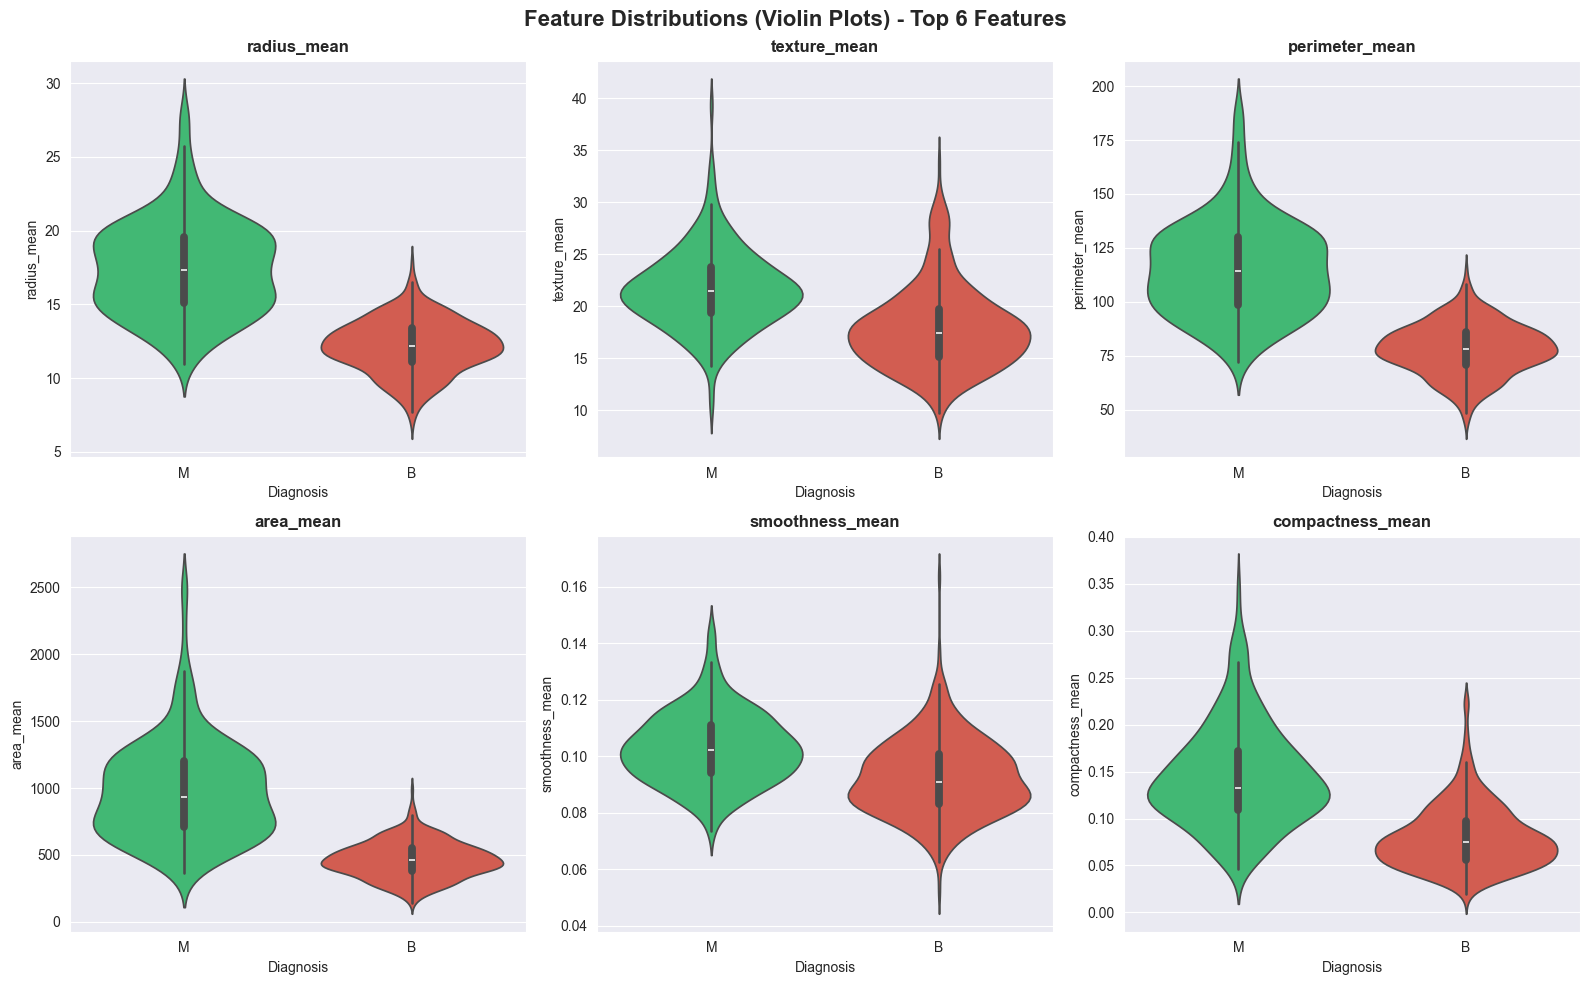

In [10]:
# Plot 3: Violin plots for top features
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for idx, feature in enumerate(mean_features[:6]):
    if feature in df.columns:
        sns.violinplot(data=df, x='Diagnosis', y=feature, palette=['#2ecc71', '#e74c3c'],
                      ax=axes[idx], inner='box', hue='Diagnosis')
        axes[idx].set_title(f'{feature}', fontsize=12, fontweight='bold')
        axes[idx].set_xlabel('Diagnosis', fontsize=10)

plt.suptitle('Feature Distributions (Violin Plots) - Top 6 Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 4. CORRELATION ANALYSIS

In [11]:
# Prepare numeric data
numeric_df = df.select_dtypes(include=[np.number])
numeric_df.columns

Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave_points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

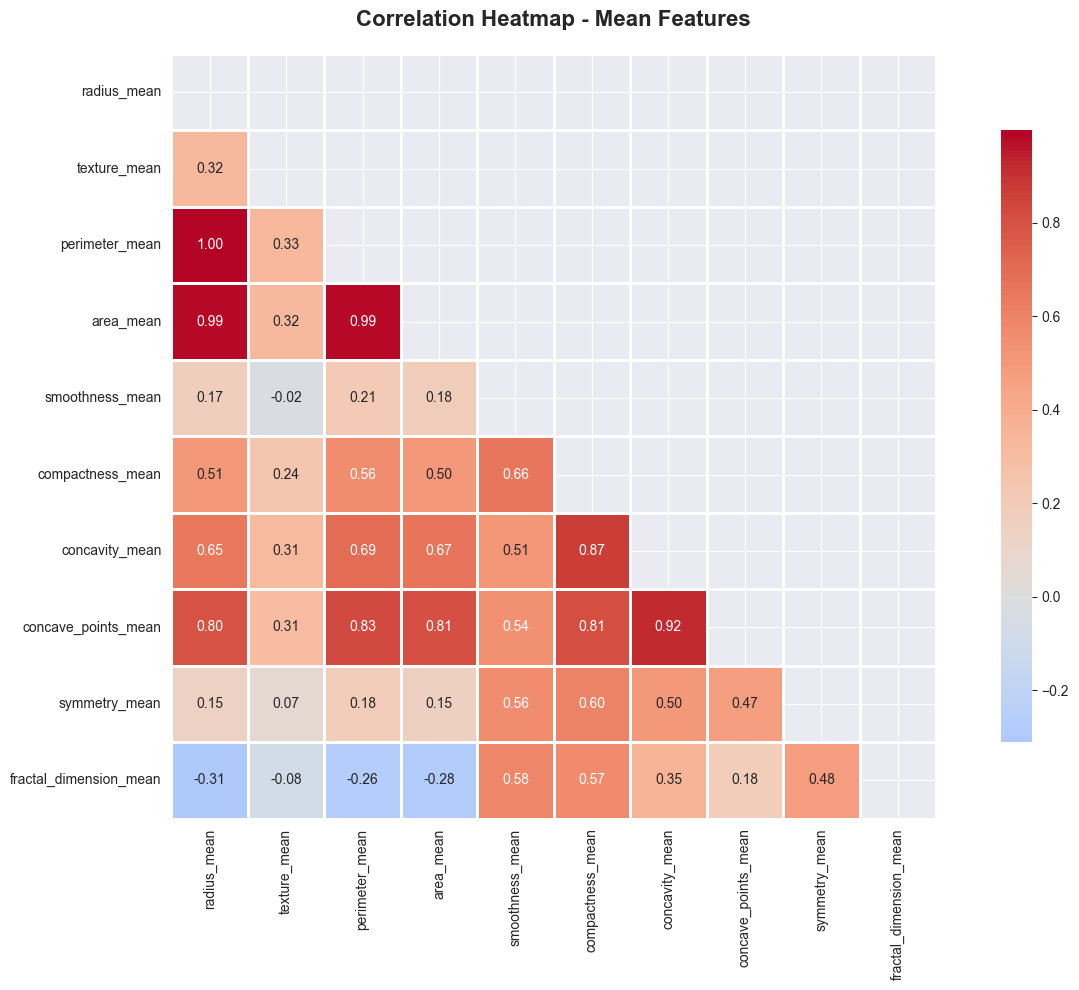

In [12]:
# Plot 4: Correlation Heatmap (Mean features only for clarity)
mean_numeric_cols = [col for col in numeric_df.columns if 'mean' in col.lower()]

plt.figure(figsize=(14, 10))
correlation_matrix = numeric_df[mean_numeric_cols].corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap - Mean Features', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [13]:
# Find strongly and weakly correlated features
strong_correlations_pairs = []
weak_correlations_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        if abs(correlation_matrix.iloc[i, j]) > 0.8:
            strong_correlations_pairs.append((correlation_matrix.columns[i],
                                   correlation_matrix.columns[j],
                                   correlation_matrix.iloc[i, j]))
        if abs(correlation_matrix.iloc[i, j]) < 0.2:
            weak_correlations_pairs.append((correlation_matrix.columns[i],
                                   correlation_matrix.columns[j],
                                   correlation_matrix.iloc[i, j]))

strong_correlations_pairs.sort(key=lambda x: x[2], reverse=True)
weak_correlations_pairs.sort(key=lambda x: x[2])

print("\nTop 10 Strongly Correlated Feature Pairs (|corr| > 0.8):")
for feat1, feat2, corr in strong_correlations_pairs[:10]:
    print(f"  {feat1} <-> {feat2}: {corr:.3f}")

print("\nTop 10 Weakly Correlated Feature Pairs (|corr| < 0.2):")
for feat1, feat2, corr in weak_correlations_pairs[:10]:
    print(f"  {feat1} <-> {feat2}: {corr:.3f}")


Top 10 Strongly Correlated Feature Pairs (|corr| > 0.8):
  radius_mean <-> perimeter_mean: 0.998
  radius_mean <-> area_mean: 0.987
  perimeter_mean <-> area_mean: 0.987
  concavity_mean <-> concave_points_mean: 0.919
  compactness_mean <-> concavity_mean: 0.868
  perimeter_mean <-> concave_points_mean: 0.827
  compactness_mean <-> concave_points_mean: 0.814
  area_mean <-> concave_points_mean: 0.807

Top 10 Weakly Correlated Feature Pairs (|corr| < 0.2):
  texture_mean <-> fractal_dimension_mean: -0.076
  texture_mean <-> smoothness_mean: -0.023
  texture_mean <-> symmetry_mean: 0.071
  radius_mean <-> symmetry_mean: 0.148
  area_mean <-> symmetry_mean: 0.151
  radius_mean <-> smoothness_mean: 0.171
  area_mean <-> smoothness_mean: 0.177
  concave_points_mean <-> fractal_dimension_mean: 0.179
  perimeter_mean <-> symmetry_mean: 0.183


### 5. PCA VISUALIZATION

In [14]:
# Prepare data for PCA - ensure no NaN values
X = numeric_df.values
y = df['Diagnosis'].map({'M': 1, 'B': 0}).values

print(f"\nData shape for PCA: {X.shape}")

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"\nExplained Variance Ratio: {pca.explained_variance_ratio_}")
print(f"Total Variance Explained: {sum(pca.explained_variance_ratio_)*100:.2f}%")


Data shape for PCA: (569, 30)

Explained Variance Ratio: [0.43861453 0.1913385 ]
Total Variance Explained: 63.00%


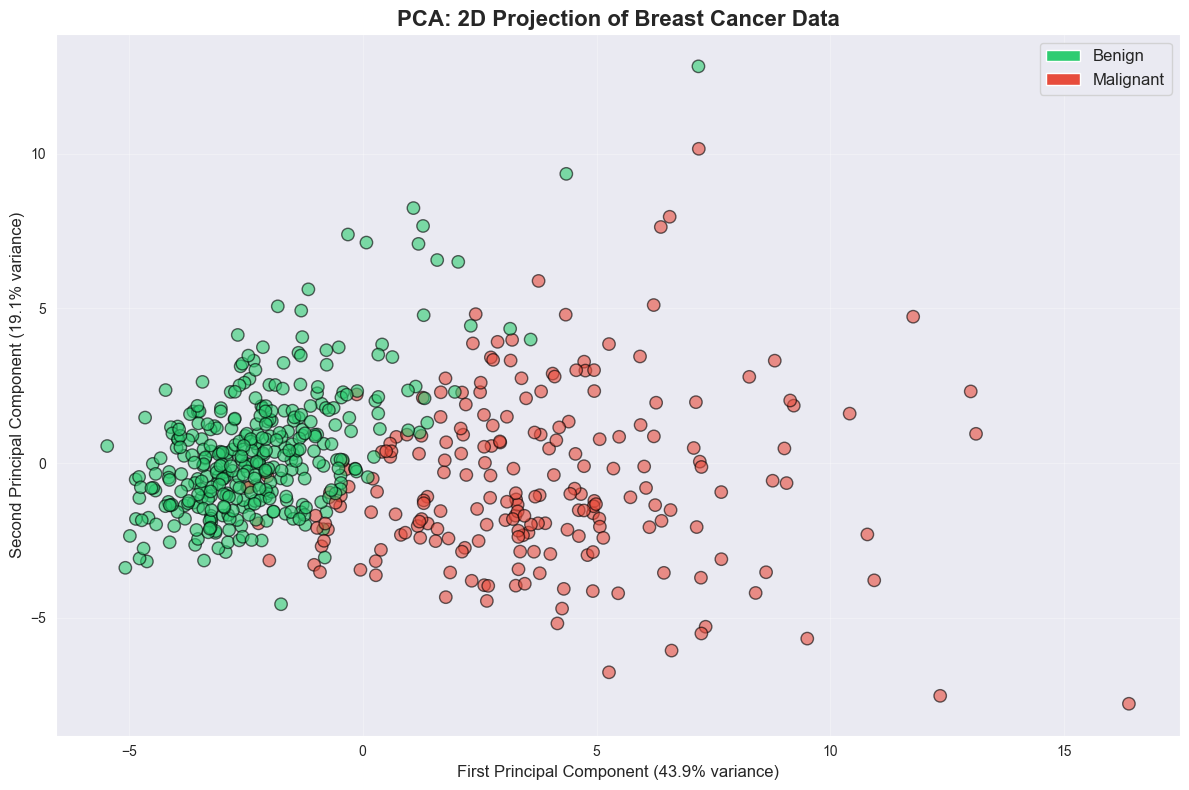

In [15]:
# Plot 5: PCA Scatter Plot
plt.figure(figsize=(12, 8))
colors = ['#2ecc71' if label == 0 else '#e74c3c' for label in y]
labels = ['Benign' if label == 0 else 'Malignant' for label in y]

scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=colors, alpha=0.6, s=80, edgecolors='black')
plt.xlabel(f'First Principal Component ({pca.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=12)
plt.ylabel(f'Second Principal Component ({pca.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=12)
plt.title('PCA: 2D Projection of Breast Cancer Data', fontsize=16, fontweight='bold')
plt.grid(alpha=0.3)

# Create legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2ecc71', label='Benign'),
                   Patch(facecolor='#e74c3c', label='Malignant')]
plt.legend(handles=legend_elements, loc='best', fontsize=12)
plt.tight_layout()
plt.show()

### 6. PAIRPLOT FOR TOP FEATURES


Creating pairplot for: ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean']


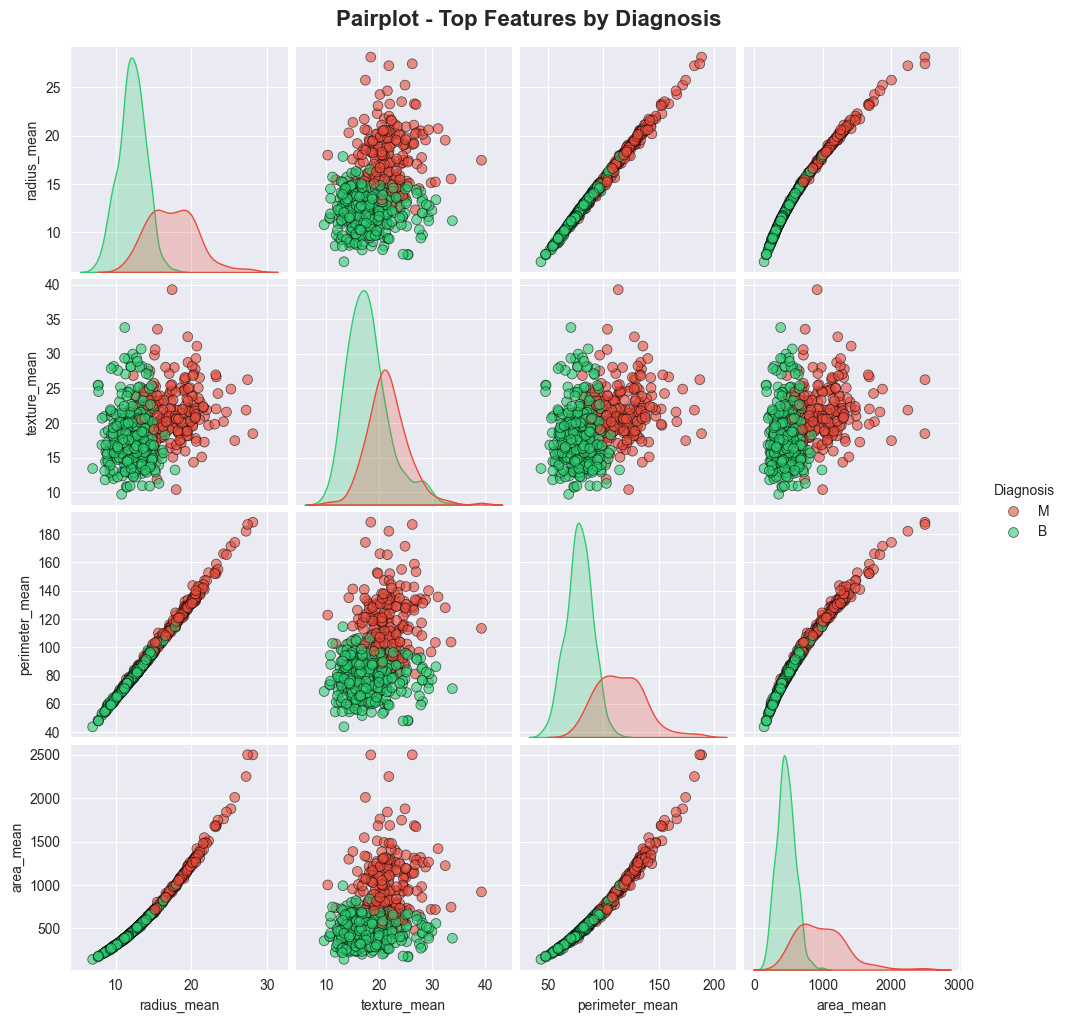

In [16]:
# Select top 4 most important features for pairplot (to keep it readable)
top_features = mean_features[:4] if len(mean_features) >= 4 else mean_features
pairplot_df = df[top_features + ['Diagnosis']].copy()

print(f"\nCreating pairplot for: {top_features}")

# Plot 6: Pairplot
pairplot = sns.pairplot(pairplot_df, hue='Diagnosis', palette={'B': '#2ecc71', 'M': '#e74c3c'},
                        diag_kind='kde', plot_kws={'alpha': 0.6, 's': 50, 'edgecolor': 'black'},
                        height=2.5)
pairplot.figure.suptitle('Pairplot - Top Features by Diagnosis', fontsize=16, fontweight='bold', y=1.02)
plt.show()

### 7. FEATURE IMPORTANCE PREVIEW (Statistical)

In [17]:
# Calculate mean difference between classes for each feature
feature_importance = {}
for col in mean_features:
    if col in df.columns:
        benign_mean = df[df['Diagnosis'] == 'B'][col].mean()
        malignant_mean = df[df['Diagnosis'] == 'M'][col].mean()
        difference = abs(malignant_mean - benign_mean)
        feature_importance[col] = difference

# Sort by importance
sorted_features = sorted(feature_importance.items(), key=lambda x: x[1], reverse=True)

print("\nTop 10 Features by Mean Difference:")
for idx, (feature, importance) in enumerate(sorted_features[:10], 1):
    print(f"{idx}. {feature}: {importance:.4f}")


Top 10 Features by Mean Difference:
1. area_mean: 515.5862
2. perimeter_mean: 37.2900
3. radius_mean: 5.3163
4. texture_mean: 3.6901
5. concavity_mean: 0.1114
6. compactness_mean: 0.0651
7. concave_points_mean: 0.0604
8. symmetry_mean: 0.0187
9. smoothness_mean: 0.0104
10. fractal_dimension_mean: 0.0002


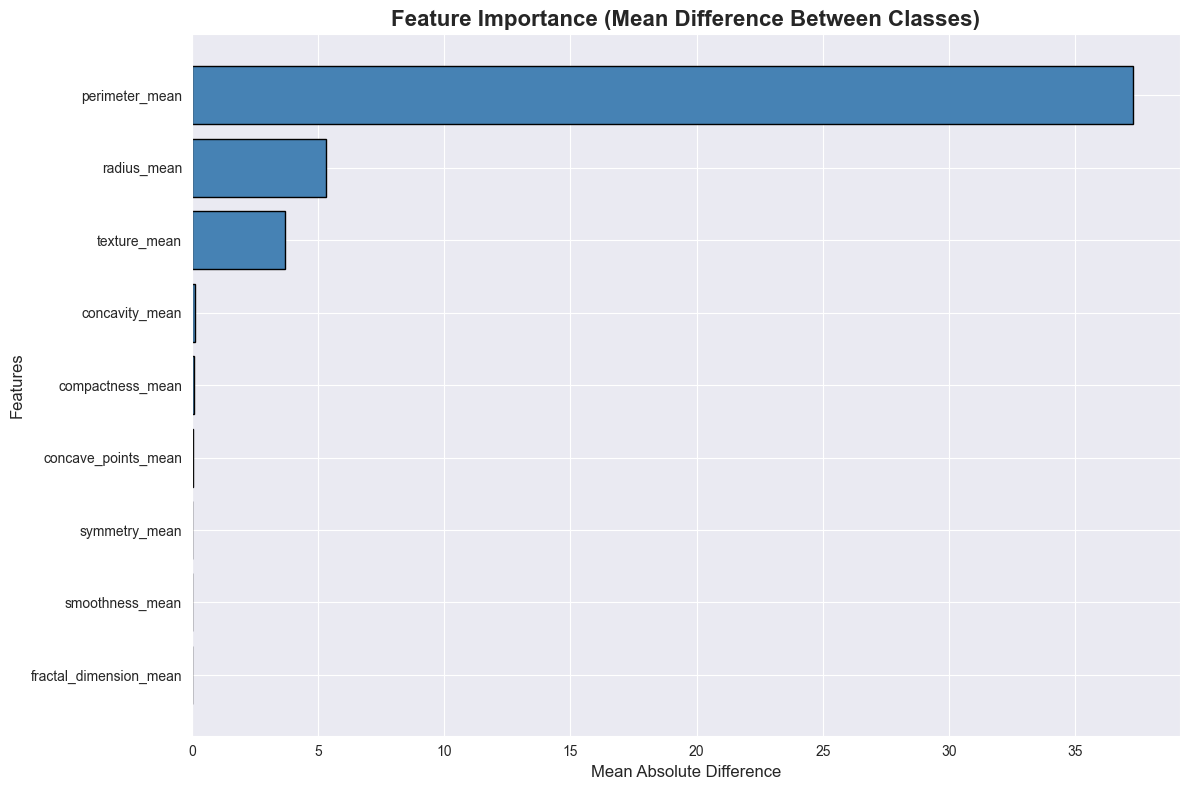

In [18]:
# Plot 7: Feature Importance Bar Plot
plt.figure(figsize=(12, 8))
sorted_features.remove(sorted_features[0])
features = [x[0] for x in sorted_features[:10]]
importances = [x[1] for x in sorted_features[:10]]

plt.barh(features, importances, color='steelblue', edgecolor='black')
plt.xlabel('Mean Absolute Difference', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.title('Feature Importance (Mean Difference Between Classes)', fontsize=16, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# MODELS TRAINING

### 1. LOAD AND PREPARE DATA

In [19]:
# Data (as pandas dataframes)
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# Combine into a single dataframe
df = pd.concat([X, y], axis=1)

feature_names = [
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean',
    'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
    'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst',
    'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]

df.columns = feature_names + ['Diagnosis']

### 2. TRAIN-TEST SPLIT & SCALING

In [20]:
# Remove columns that are entirely NaN or have too many missing values
print("\n[CLEANING DATA]")
initial_shape = df.shape
df = df.dropna(axis=1, how='all')  # Drop columns with all NaN
print(f"Dropped columns with all NaN values: {initial_shape[1] - df.shape[1]} columns")

# Remove 'Unnamed' columns that are often artifacts
unnamed_cols = [col for col in df.columns if 'Unnamed' in col]
if unnamed_cols:
    df = df.drop(columns=unnamed_cols)
    print(f"Dropped unnamed columns: {unnamed_cols}")

if 'id' in df.columns:
    df = df.drop('id', axis=1)
    print("Dropped 'id' column")

# Handle missing values
print("\n[DATA CLEANING]")
numeric_cols = df.select_dtypes(include=[np.number]).columns

# Handle zero values - replace with column mean
zero_counts = (df[numeric_cols] == 0).sum()
columns_with_zeros = zero_counts[zero_counts > 0]

if len(columns_with_zeros) > 0:
    print(f"\nFound zero values in {len(columns_with_zeros)} columns")
    print("Replacing zeros with column means (excluding zeros)")

    for col in columns_with_zeros.index:
        zero_mask = df[col] == 0
        if zero_mask.any():
            # Calculate mean excluding zeros
            col_mean = df[col][df[col] != 0].mean()
            df.loc[zero_mask, col] = col_mean

    print(f"Replaced {zero_counts.sum()} zero values with column means")
else:
    print("No zero values found in numeric columns")

# Prepare features and target
X = df.drop('Diagnosis', axis=1)
y = df['Diagnosis']

# Encode target variable
le = LabelEncoder()
y_encoded = le.fit_transform(y)  # M=1, B=0
print(f"\nLabel encoding: {dict(zip(le.classes_, le.transform(le.classes_)))}")


[CLEANING DATA]
Dropped columns with all NaN values: 0 columns

[DATA CLEANING]

Found zero values in 6 columns
Replacing zeros with column means (excluding zeros)
Replaced 78 zero values with column means

Label encoding: {'B': np.int64(0), 'M': np.int64(1)}


In [34]:
print("\n[2] SPLITTING DATA (70% train, 30% test)")
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")

# Standardize features (crucial for SVM)
print("\n[3] STANDARDIZING FEATURES")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled


[2] SPLITTING DATA (70% train, 30% test)
Training set: (398, 30)
Test set: (171, 30)

[3] STANDARDIZING FEATURES


array([[ 1.70581999,  1.04974466,  2.12129465, ...,  2.09120016,
         3.94428119,  0.86655367],
       [ 0.53638811, -0.90994477,  0.5690952 , ...,  1.26170898,
         0.16797759,  0.40524244],
       [-0.13145612, -0.99333581, -0.14884823, ..., -0.19737701,
         0.74198821,  0.68752098],
       ...,
       [-0.31743806,  1.31844912, -0.38065427, ..., -0.92440162,
        -0.944168  , -1.15058462],
       [ 0.02071092,  0.25289695,  0.02070601, ...,  0.2512093 ,
        -0.58853098, -0.2900195 ],
       [ 1.59592158,  1.3161327 ,  1.57659141, ...,  0.86978621,
         0.61408367,  0.04333279]], shape=(398, 30))

### 3. SVM MODEL TRAINING

In [22]:
 # Train baseline SVM
svm_baseline = SVC(kernel='rbf', random_state=42, probability=True)
svm_baseline.fit(X_train_scaled, y_train)

# Baseline predictions
y_pred_svm_baseline = svm_baseline.predict(X_test_scaled)
y_proba_svm_baseline = svm_baseline.predict_proba(X_test_scaled)[:, 1]

# Show confusion matrix breakdown
cm_svm_baseline = confusion_matrix(y_test, y_pred_svm_baseline)
tn, fp, fn, tp = cm_svm_baseline.ravel()

print("\nBASELINE SVM RESULTS (rbf)")
print("\nConfusion Matrix Breakdown:")
print(f"True Negatives (TN): {tn} | False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn} | True Positives (TP): {tp}")
print(f"\nMetrics:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_svm_baseline):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm_baseline, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_svm_baseline):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_svm_baseline):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_svm_baseline):.4f}")


print(classification_report(y_test, y_pred_svm_baseline, target_names=['Benign', 'Malignant']))


BASELINE SVM RESULTS (rbf)

Confusion Matrix Breakdown:
True Negatives (TN): 107 | False Positives (FP): 0
False Negatives (FN): 7 | True Positives (TP): 57

Metrics:
Accuracy: 0.9591
Precision: 1.0000
Recall: 0.8906
F1-Score: 0.9421
ROC-AUC: 0.9971
              precision    recall  f1-score   support

      Benign       0.94      1.00      0.97       107
   Malignant       1.00      0.89      0.94        64

    accuracy                           0.96       171
   macro avg       0.97      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171



In [23]:
# Hyperparameter Tuning with GridSearchCV
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear', 'poly']
}

grid_search = GridSearchCV(
    SVC(random_state=42, probability=True),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train_scaled, y_train)

print(f"\nBest Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation Score: {grid_search.best_score_:.4f}")

svm_best = grid_search.best_estimator_

# Predictions with boosted model
y_pred_svm_best = svm_best.predict(X_test_scaled)
y_proba_svm_best = svm_best.predict_proba(X_test_scaled)[:, 1]

# Show confusion matrix breakdown
cm_svm_best = confusion_matrix(y_test, y_pred_svm_best)
tn_best, fp_best, fn_best, tp_best = cm_svm_best.ravel()


Best Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best Cross-Validation Score: 0.9722


#### THE RESULTS FROM THE OPTIMIZED VERSION ARE EQUALS TO THE BASELINE

so the print will be useless

In [24]:
# print("\n--- OPTIMIZED SVM RESULTS ---")
# print(f"Kernel: {grid_search.best_params_['kernel']}")
# print(f"C: {grid_search.best_params_['C']}")
# print(f"Gamma: {grid_search.best_params_['gamma']}")
# print(f"\nConfusion Matrix Breakdown:")
# print(f"True Negatives (TN): {tn_best} | False Positives (FP): {fp_best}")
# print(f"False Negatives (FN): {fn_best} | True Positives (TP): {tp_best}")
# print(f"\nMetrics:")
# print(f"Accuracy: {accuracy_score(y_test, y_pred_svm_best):.4f}")
# print(f"Precision: {precision_score(y_test, y_pred_svm_best, zero_division=0):.4f}")
# print(f"Recall: {recall_score(y_test, y_pred_svm_best):.4f}")
# print(f"F1-Score: {f1_score(y_test, y_pred_svm_best):.4f}")
# print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_svm_best):.4f}")

# print(classification_report(y_test, y_pred_svm_best, target_names=['Benign', 'Malignant']))

In [25]:
# Cross-validation scores
# cv_scores = cross_val_score(svm_best, X_train_scaled, y_train, cv=5, scoring='accuracy')
# print(f"CV Scores: {cv_scores}")
# print(f"Mean CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

### 4. NEURAL NETWORK

In [26]:
# Train baseline Neural Network
mlp_baseline = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='sgd',
    alpha=0.01,
    learning_rate_init=0.01,
    max_iter=2000,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10
)

mlp_baseline.fit(X_train_scaled, y_train)

# Baseline NN predictions
y_pred_mlp_baseline = mlp_baseline.predict(X_test_scaled)
y_proba_mlp_baseline = mlp_baseline.predict_proba(X_test_scaled)[:, 1]

# Show confusion matrix breakdown
cm_mlp_baseline = confusion_matrix(y_test, y_pred_mlp_baseline)
tn, fp, fn, tp = cm_mlp_baseline.ravel()

print("\nBASELINE NEURAL NETWORK RESULTS")
print(f"Training iterations: {mlp_baseline.n_iter_}")
print(f"Training loss: {mlp_baseline.loss_:.4f}")
print(f"\nConfusion Matrix Breakdown:")
print(f"True Negatives (TN): {tn} | False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn} | True Positives (TP): {tp}")
print(f"\nMetrics:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_mlp_baseline):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_mlp_baseline, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_mlp_baseline):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_mlp_baseline):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_mlp_baseline):.4f}")


BASELINE NEURAL NETWORK RESULTS
Training iterations: 23
Training loss: 0.1167

Confusion Matrix Breakdown:
True Negatives (TN): 105 | False Positives (FP): 2
False Negatives (FN): 8 | True Positives (TP): 56

Metrics:
Accuracy: 0.9415
Precision: 0.9655
Recall: 0.8750
F1-Score: 0.9180
ROC-AUC: 0.9902


In [27]:
# Hyperparameter Tuning for Neural Network
mlp_param_grid = {
    'hidden_layer_sizes': [(16,), (32,), (64,), (16, 8), (32, 16), (64, 32)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001, 0.01],  # L2 regularization
    'learning_rate_init': [0.001, 0.01]
}

mlp_grid_search = GridSearchCV(
    MLPClassifier(solver='adam', max_iter=1000, random_state=42, early_stopping=True),
    mlp_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

mlp_grid_search.fit(X_train_scaled, y_train)

print(f"\nBest Parameters: {mlp_grid_search.best_params_}")
print(f"Best Cross-Validation Score: {mlp_grid_search.best_score_:.4f}")

# Best Neural Network model
mlp_best = mlp_grid_search.best_estimator_

# Predictions with best NN
y_pred_mlp_best = mlp_best.predict(X_test_scaled)
y_proba_mlp_best = mlp_best.predict_proba(X_test_scaled)[:, 1]

# Show confusion matrix breakdown
cm_mlp_best = confusion_matrix(y_test, y_pred_mlp_best)
tn_best, fp_best, fn_best, tp_best = cm_mlp_best.ravel()

print("\nOPTIMIZED NEURAL NETWORK RESULTS")
print(f"Architecture: {mlp_grid_search.best_params_['hidden_layer_sizes']}")
print(f"Activation: {mlp_grid_search.best_params_['activation']}")
print(f"Alpha (L2): {mlp_grid_search.best_params_['alpha']}")
print(f"Learning Rate: {mlp_grid_search.best_params_['learning_rate_init']}")
print(f"Training iterations: {mlp_best.n_iter_}")
print(f"Training loss: {mlp_best.loss_:.4f}")
print(f"\nConfusion Matrix Breakdown:")
print(f"True Negatives (TN): {tn_best} | False Positives (FP): {fp_best}")
print(f"False Negatives (FN): {fn_best} | True Positives (TP): {tp_best}")
print(f"\nMetrics:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_mlp_best):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_mlp_best, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_mlp_best):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_mlp_best):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_mlp_best):.4f}")

Fitting 5 folds for each of 72 candidates, totalling 360 fits

Best Parameters: {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.01}
Best Cross-Validation Score: 0.9698

OPTIMIZED NEURAL NETWORK RESULTS
Architecture: (64,)
Activation: tanh
Alpha (L2): 0.0001
Learning Rate: 0.01
Training iterations: 19
Training loss: 0.0557

Confusion Matrix Breakdown:
True Negatives (TN): 106 | False Positives (FP): 1
False Negatives (FN): 4 | True Positives (TP): 60

Metrics:
Accuracy: 0.9708
Precision: 0.9836
Recall: 0.9375
F1-Score: 0.9600
ROC-AUC: 0.9982


In [28]:
# Cross-validation for best NN
print("\n[9] NEURAL NETWORK CROSS-VALIDATION (5-Fold)")
mlp_cv_scores = cross_val_score(mlp_best, X_train_scaled, y_train, cv=5, scoring='accuracy')
print(f"CV Scores: {mlp_cv_scores}")
print(f"Mean CV Score: {mlp_cv_scores.mean():.4f} (+/- {mlp_cv_scores.std() * 2:.4f})")


[9] NEURAL NETWORK CROSS-VALIDATION (5-Fold)
CV Scores: [0.95       1.         0.975      0.96202532 0.96202532]
Mean CV Score: 0.9698 (+/- 0.0341)


### 5. MODEL COMPARISON SUMMARY


         Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
SVM (Baseline)  0.959064   1.000000 0.890625  0.942149 0.997079
 NN (Baseline)  0.941520   0.965517 0.875000  0.918033 0.990216
NN (Optimized)  0.970760   0.983607 0.937500  0.960000 0.998248


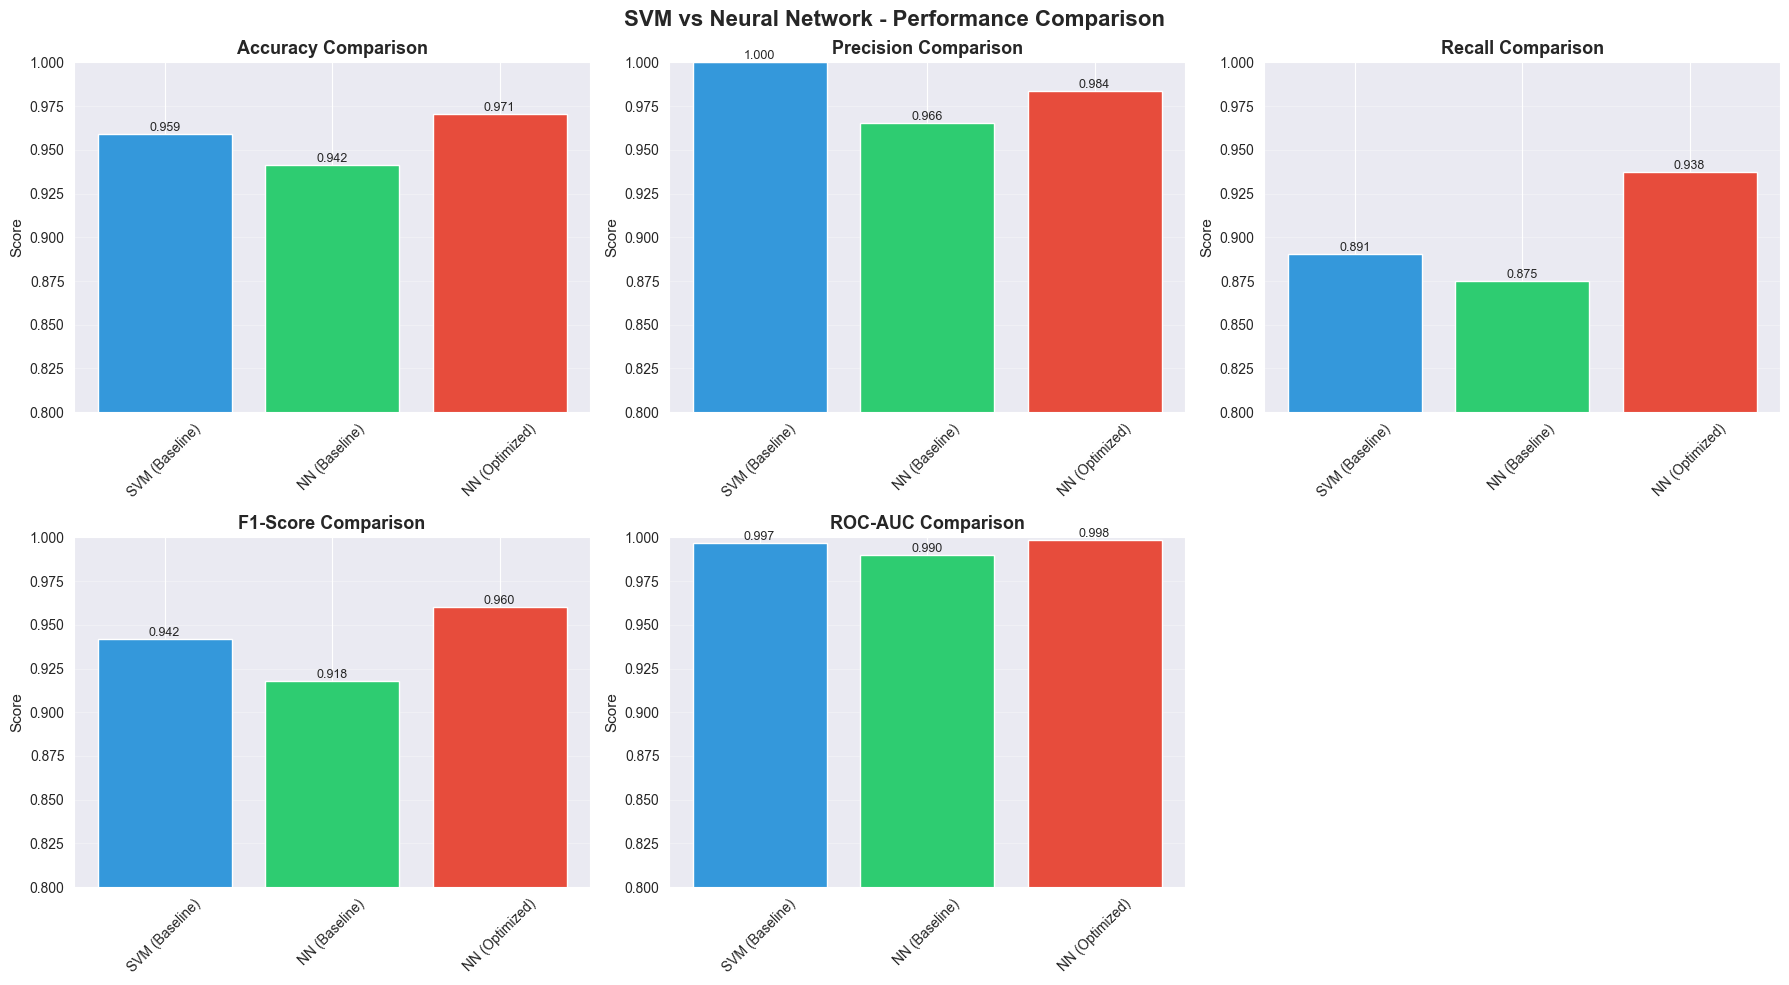

In [29]:
comparison_df = pd.DataFrame({
    'Model': ['SVM (Baseline)', 'NN (Baseline)', 'NN (Optimized)'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_svm_baseline),
        # accuracy_score(y_test, y_pred_svm_best),
        accuracy_score(y_test, y_pred_mlp_baseline),
        accuracy_score(y_test, y_pred_mlp_best)
    ],
    'Precision': [
        precision_score(y_test, y_pred_svm_baseline, zero_division=0),
        # precision_score(y_test, y_pred_svm_best, zero_division=0),
        precision_score(y_test, y_pred_mlp_baseline, zero_division=0),
        precision_score(y_test, y_pred_mlp_best, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred_svm_baseline),
        # recall_score(y_test, y_pred_svm_best),
        recall_score(y_test, y_pred_mlp_baseline),
        recall_score(y_test, y_pred_mlp_best)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_svm_baseline),
        # f1_score(y_test, y_pred_svm_best),
        f1_score(y_test, y_pred_mlp_baseline),
        f1_score(y_test, y_pred_mlp_best)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_proba_svm_baseline),
        # roc_auc_score(y_test, y_proba_svm_best),
        roc_auc_score(y_test, y_proba_mlp_baseline),
        roc_auc_score(y_test, y_proba_mlp_best)
    ]
})

print("\n" + comparison_df.to_string(index=False))

# Visualize comparison
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
colors = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12']

for idx, metric in enumerate(metrics):
    ax = axes[idx // 3, idx % 3]
    bars = ax.bar(comparison_df['Model'], comparison_df[metric], color=colors)
    ax.set_title(f'{metric} Comparison', fontsize=13, fontweight='bold')
    ax.set_ylabel('Score', fontsize=11)
    ax.set_ylim([0.8, 1.0])
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)

    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9)

# Remove empty subplot
fig.delaxes(axes[1, 2])

plt.suptitle('SVM vs Neural Network - Performance Comparison', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 6. GENERATING MODEL COMPARISON VISUALIZATIONS

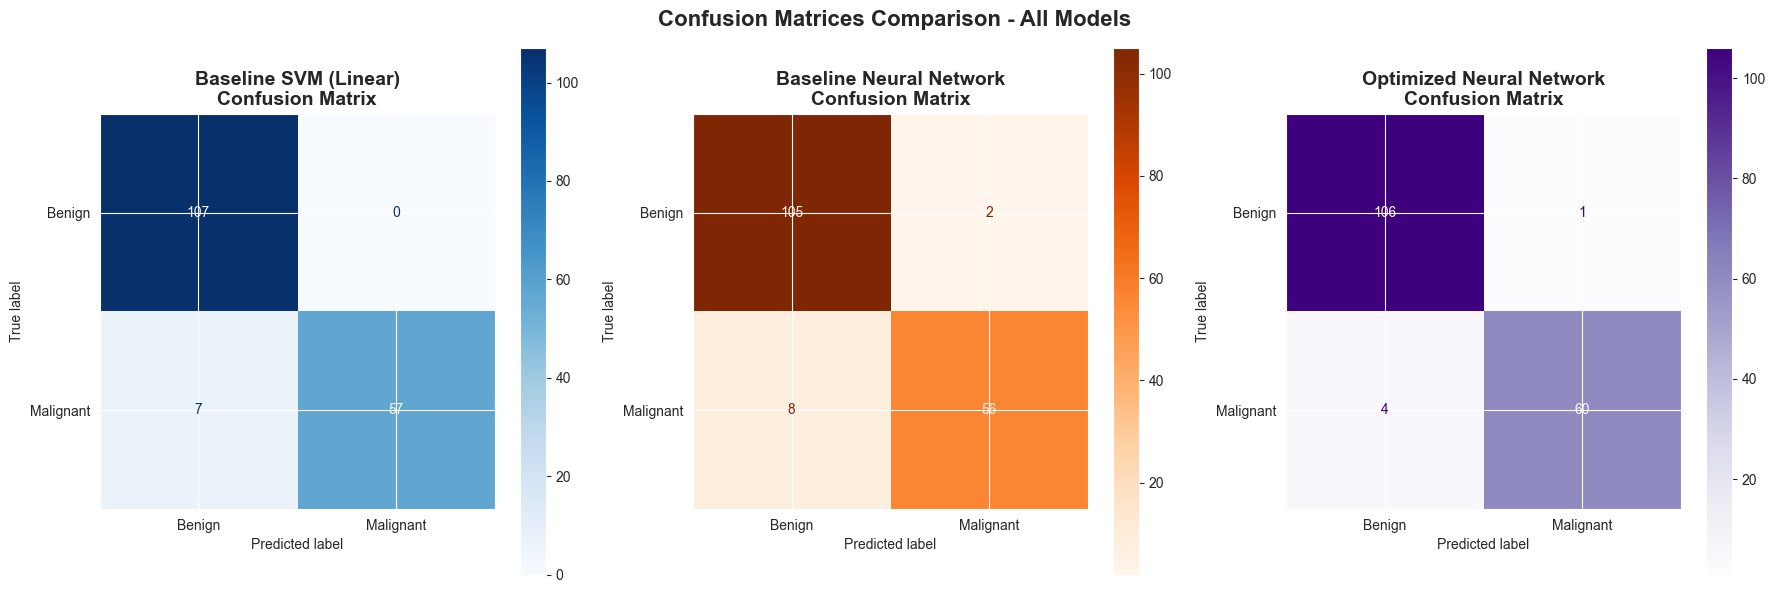

In [30]:
# Plot 1: Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Baseline SVM
ConfusionMatrixDisplay(cm_svm_baseline, display_labels=['Benign', 'Malignant']).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Baseline SVM (Linear)\nConfusion Matrix', fontsize=14, fontweight='bold')

# Optimized SVM
# ConfusionMatrixDisplay(cm_svm_best, display_labels=['Benign', 'Malignant']).plot(ax=axes[1], cmap='Greens')
# axes[1].set_title('Optimized SVM (RBF)\nConfusion Matrix', fontsize=14, fontweight='bold')

# Baseline Neural Network
ConfusionMatrixDisplay(cm_mlp_baseline, display_labels=['Benign', 'Malignant']).plot(ax=axes[1], cmap='Oranges')
axes[1].set_title('Baseline Neural Network\nConfusion Matrix', fontsize=14, fontweight='bold')

# Optimized Neural Network
ConfusionMatrixDisplay(cm_mlp_best, display_labels=['Benign', 'Malignant']).plot(ax=axes[2], cmap='Purples')
axes[2].set_title('Optimized Neural Network\nConfusion Matrix', fontsize=14, fontweight='bold')

plt.suptitle('Confusion Matrices Comparison - All Models', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

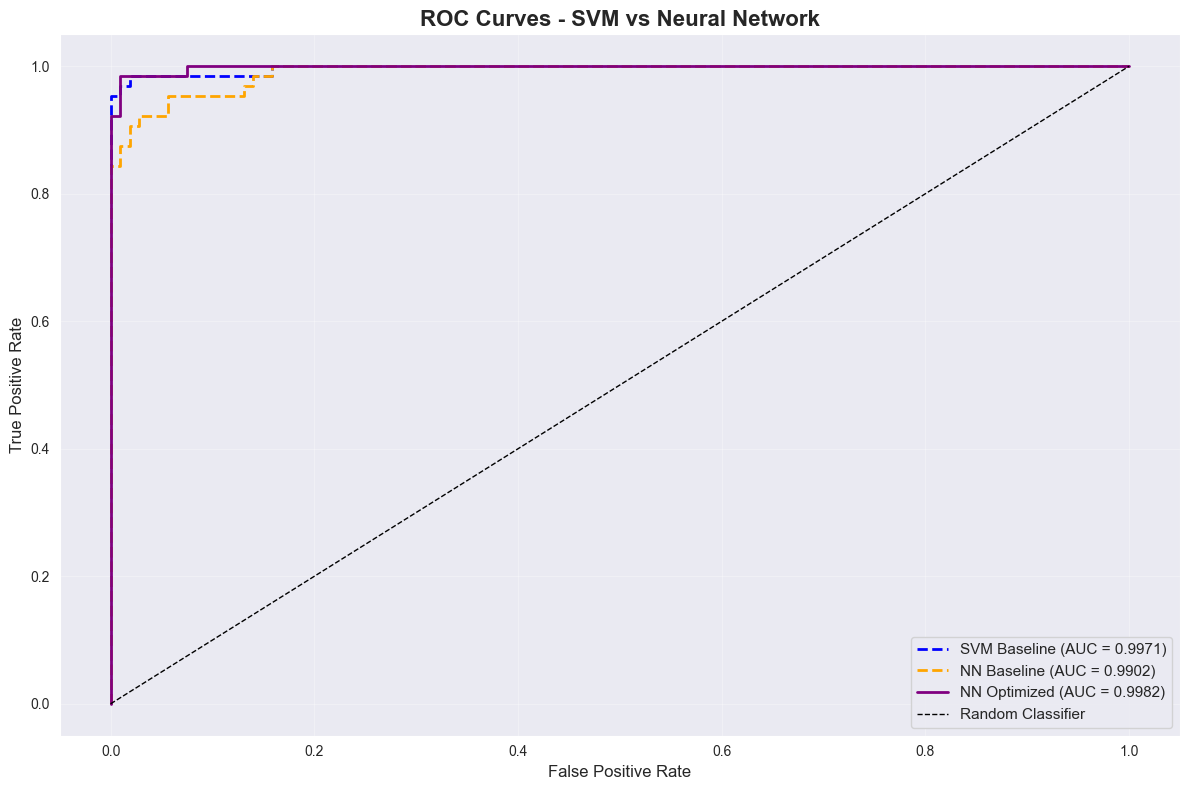

In [31]:
# Plot 2: ROC Curves - All Models
plt.figure(figsize=(12, 8))

# SVM Baseline
fpr_baseline, tpr_baseline, _ = roc_curve(y_test, y_proba_svm_baseline)
roc_auc_baseline = roc_auc_score(y_test, y_proba_svm_baseline)

# SVM Optimized
# fpr_best, tpr_best, _ = roc_curve(y_test, y_proba_svm_best)
# roc_auc_best = roc_auc_score(y_test, y_proba_svm_best)

# NN Baseline
fpr_mlp_baseline, tpr_mlp_baseline, _ = roc_curve(y_test, y_proba_mlp_baseline)
roc_auc_mlp_baseline = roc_auc_score(y_test, y_proba_mlp_baseline)

# NN Optimized
fpr_mlp_best, tpr_mlp_best, _ = roc_curve(y_test, y_proba_mlp_best)
roc_auc_mlp_best = roc_auc_score(y_test, y_proba_mlp_best)

plt.plot(fpr_baseline, tpr_baseline, label=f'SVM Baseline (AUC = {roc_auc_baseline:.4f})',
         linewidth=2, color='blue', linestyle='--')
# plt.plot(fpr_best, tpr_best, label=f'SVM Optimized (AUC = {roc_auc_best:.4f})',
#          linewidth=2, color='green')
plt.plot(fpr_mlp_baseline, tpr_mlp_baseline, label=f'NN Baseline (AUC = {roc_auc_mlp_baseline:.4f})',
         linewidth=2, color='orange', linestyle='--')
plt.plot(fpr_mlp_best, tpr_mlp_best, label=f'NN Optimized (AUC = {roc_auc_mlp_best:.4f})',
         linewidth=2, color='purple')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier', linewidth=1)

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves - SVM vs Neural Network', fontsize=16, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
# Plot 3: Detailed Classification Reports
print("\n>>> OPTIMIZED SVM:")
print(classification_report(y_test, y_pred_svm_best, target_names=['Benign', 'Malignant']))
print("\n>>> OPTIMIZED NEURAL NETWORK:")
print(classification_report(y_test, y_pred_mlp_best, target_names=['Benign', 'Malignant']))


>>> OPTIMIZED SVM:
              precision    recall  f1-score   support

      Benign       0.94      1.00      0.97       107
   Malignant       1.00      0.89      0.94        64

    accuracy                           0.96       171
   macro avg       0.97      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171


>>> OPTIMIZED NEURAL NETWORK:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.98       107
   Malignant       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171

